# Ames 주택 가격 예측

### 목적
집의 특징 79개(면적, 품질, 위치, 건축연도 등)로 미국 Ames 지역 주택의 **판매가(SalePrice)를 예측**한다.

- 학습 데이터: train.csv 1,168채
- 예측 대상: test.csv 292채

### 평가지표
**RMSE (Root Mean Squared Error, 달러 단위)** — 낮을수록 좋다.

$$RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}$$

오차를 제곱해서 평균을 낸 뒤 제곱근을 씌우므로, **크게 틀린 예측(특히 비싼 집)에 큰 벌점**이 붙는다.

---
## 1. 데이터 확인

In [1]:
# ===== 1-0. 라이브러리 / 데이터 불러오기 =====
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid')   # Kaggle에는 한글 폰트가 없으므로 그래프 글자는 영어로

found = glob.glob('/kaggle/input/**/train.csv', recursive=True)
DATA_DIR = os.path.dirname(found[0]) if found else '.'
train_df = pd.read_csv(os.path.join(DATA_DIR, 'train.csv'))
test_df  = pd.read_csv(os.path.join(DATA_DIR, 'test.csv'))

print('train:', train_df.shape, '/ test:', test_df.shape)
num_cols = train_df.drop(columns=['Id', 'SalePrice']).select_dtypes(include='number').columns
cat_cols = train_df.select_dtypes(exclude='number').columns
print(f'수치형 {len(num_cols)}개 / 범주형 {len(cat_cols)}개')
print('train/test Id 중복:', len(set(train_df['Id']) & set(test_df['Id'])))


train: (1168, 81) / test: (292, 80)
수치형 36개 / 범주형 43개
train/test Id 중복: 0


**데이터 확인:** train 1,168채, test 292채. 수치형 36개, 범주형 43개 변수. train과 test의 Id가 겹치지 않아 같은 집이 양쪽에 들어있지 않다.

In [2]:
# ===== 1-1. 데이터 분리 (EDA 전에 먼저 분리 → 검증 데이터는 EDA에서도 보지 않음) =====
from sklearn.model_selection import train_test_split

X = train_df.drop(columns=['SalePrice', 'Id'])        # 입력 (Id는 집 번호라 제외)
y = train_df['SalePrice']                              # 정답
test_id = test_df['Id']                                # 제출용 Id 보관
X_test = test_df.drop(columns=['Id'])

# MSSubClass: 숫자로 된 '주택 유형 번호표' → 문자열(범주)
X['MSSubClass'] = X['MSSubClass'].astype(str)
X_test['MSSubClass'] = X_test['MSSubClass'].astype(str)

# 학습 80% / 검증(holdout) 20%
X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, random_state=42)
print('X_tr:', X_tr.shape, '/ X_val:', X_val.shape, '/ X_test:', X_test.shape)


# EDA용: 학습 데이터(934채)만 정답과 합쳐서 사용
eda_df = pd.concat([X_tr, y_tr], axis=1)
print('EDA 데이터:', eda_df.shape)


X_tr: (934, 79) / X_val: (234, 79) / X_test: (292, 79)
EDA 데이터: (934, 80)


**왜 EDA 전에 분리했나:** 검증 데이터(234채)는 모델 설정을 정할 때 '처음 보는 집'으로 확인하는 데 썼다. EDA에서 검증 데이터를 보고 전처리 방법을 정하면 그 결정에 검증 데이터 정보가 섞이므로, EDA부터 학습 데이터 934채만 사용했다. 설정을 모두 정한 뒤 최종 학습(4-2)에서는 검증 데이터도 함께 학습한다.

- 학습 80% (934채) / 검증 20% (234채), `random_state=42`로 고정
- `MSSubClass`는 숫자지만 '주택 유형 번호표'라 크기에 의미가 없어 문자열(범주)로 바꿨다

count       934.0
mean     178345.0
std       80681.0
min       34900.0
25%      128912.0
50%      160000.0
75%      207000.0
max      755000.0
Name: SalePrice, dtype: float64


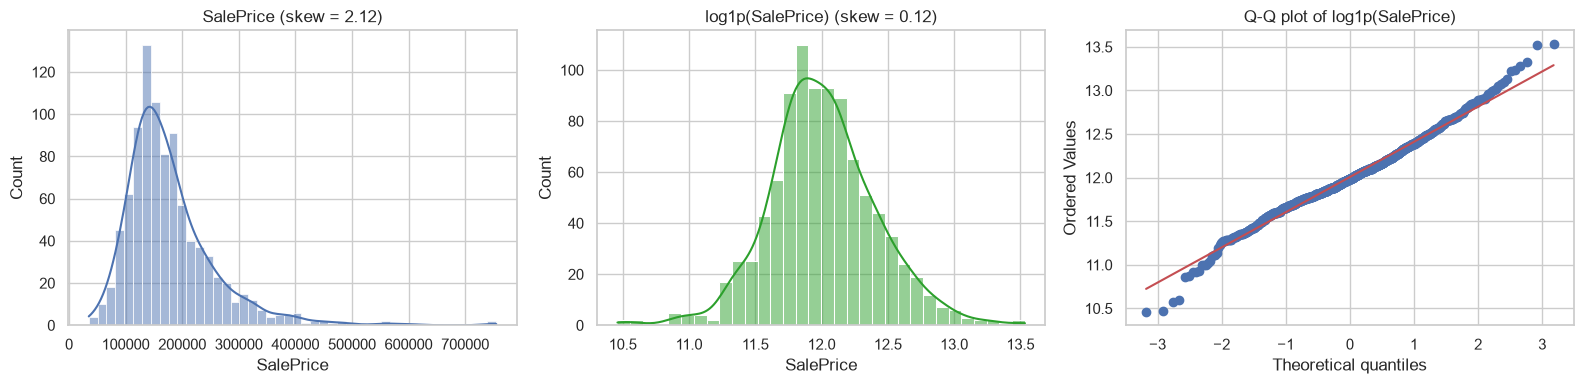

In [3]:
# ===== 1-2. 타겟(SalePrice) 분포 =====
y_raw = eda_df['SalePrice']
print(y_raw.describe().round(0))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(y_raw, kde=True, ax=axes[0])
axes[0].set_title(f'SalePrice (skew = {y_raw.skew():.2f})')
sns.histplot(np.log1p(y_raw), kde=True, ax=axes[1], color='tab:green')
axes[1].set_title(f'log1p(SalePrice) (skew = {np.log1p(y_raw).skew():.2f})')
stats.probplot(np.log1p(y_raw), plot=axes[2])
axes[2].set_title('Q-Q plot of log1p(SalePrice)')
plt.tight_layout(); plt.show()


**타겟 분포 해석**

- 평균 178,345달러 > 중앙값 160,000달러, 최고가 755,000달러 → 비싼 집 쪽으로 **꼬리가 긴 분포** (왜도 2.12)
- `log1p` 변환 후 왜도 0.12로 거의 좌우 대칭이 되고, Q-Q plot도 직선에 가까워진다
- → **타겟을 log로 바꿔서 학습**하는 것을 3단계에서 비교한다 (선형 모델은 오차가 고르게 퍼져 있을 때 잘 맞기 때문)

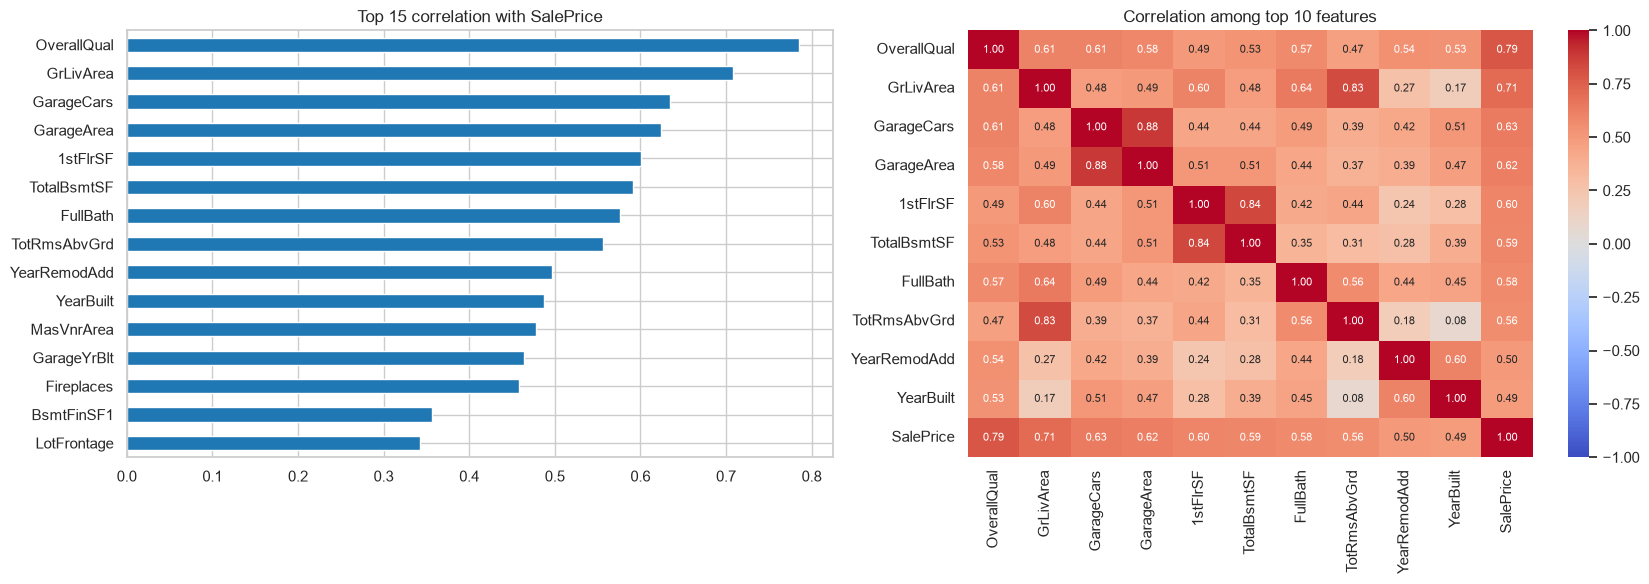

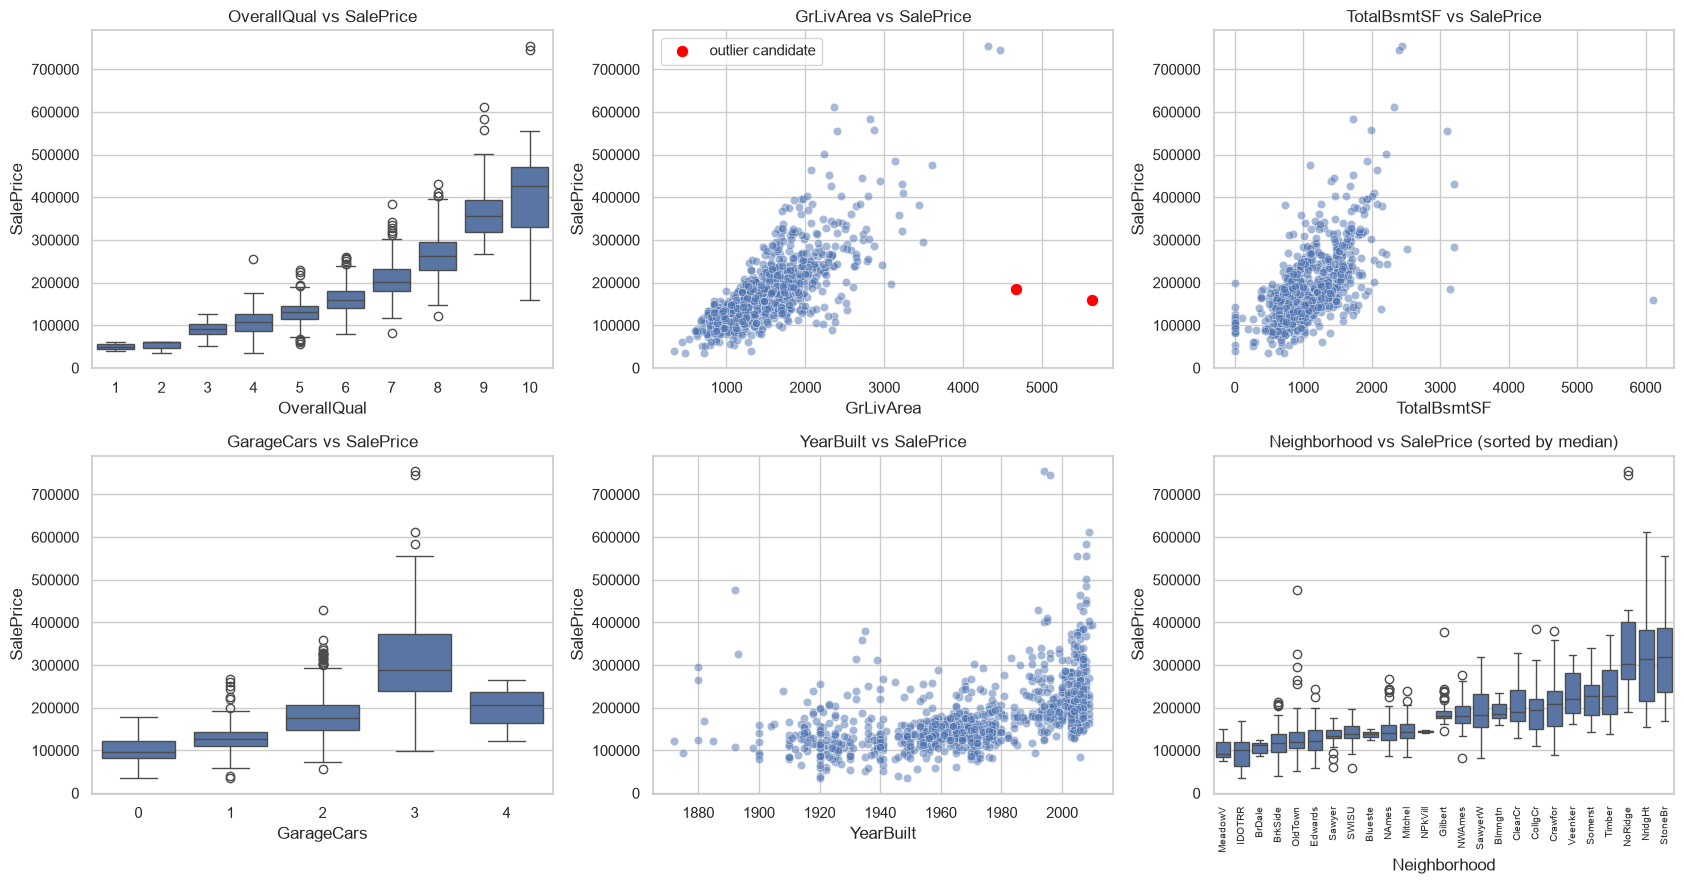

이상치 후보 (학습 데이터):
     GrLivArea  OverallQual SaleCondition  SalePrice
373       4676           10       Partial     184750
64        5642           10       Partial     160000
test에서 GrLivArea > 4000인 집 수: 0


In [4]:
# ===== 1-3. SalePrice와 관계가 강한 변수 =====
corr = eda_df[list(num_cols) + ['SalePrice']].corr()['SalePrice'].drop('SalePrice')
top_corr = corr.abs().sort_values(ascending=False).head(15)

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
corr[top_corr.index].plot.barh(ax=axes[0], color='tab:blue')
axes[0].invert_yaxis()
axes[0].set_title('Top 15 correlation with SalePrice')
top10 = list(top_corr.index[:10]) + ['SalePrice']
sns.heatmap(eda_df[top10].corr(), annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, ax=axes[1], annot_kws={'size': 8})
axes[1].set_title('Correlation among top 10 features')
plt.tight_layout(); plt.show()

# 주요 변수와 가격의 관계 + 이상치 후보
outlier_flag = (eda_df['GrLivArea'] > 4000) & (eda_df['SalePrice'] < 300000)

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
sns.boxplot(data=eda_df, x='OverallQual', y='SalePrice', ax=axes[0, 0])
axes[0, 0].set_title('OverallQual vs SalePrice')
sns.scatterplot(data=eda_df, x='GrLivArea', y='SalePrice', ax=axes[0, 1], alpha=0.5)
sns.scatterplot(data=eda_df[outlier_flag], x='GrLivArea', y='SalePrice',
                ax=axes[0, 1], color='red', s=80, label='outlier candidate')
axes[0, 1].set_title('GrLivArea vs SalePrice')
sns.scatterplot(data=eda_df, x='TotalBsmtSF', y='SalePrice', ax=axes[0, 2], alpha=0.5)
axes[0, 2].set_title('TotalBsmtSF vs SalePrice')
sns.boxplot(data=eda_df, x='GarageCars', y='SalePrice', ax=axes[1, 0])
axes[1, 0].set_title('GarageCars vs SalePrice')
sns.scatterplot(data=eda_df, x='YearBuilt', y='SalePrice', ax=axes[1, 1], alpha=0.5)
axes[1, 1].set_title('YearBuilt vs SalePrice')
order = eda_df.groupby('Neighborhood')['SalePrice'].median().sort_values().index
sns.boxplot(data=eda_df, x='Neighborhood', y='SalePrice', order=order, ax=axes[1, 2])
axes[1, 2].tick_params(axis='x', rotation=90, labelsize=7)
axes[1, 2].set_title('Neighborhood vs SalePrice (sorted by median)')
plt.tight_layout(); plt.show()

print('이상치 후보 (학습 데이터):')
print(eda_df.loc[outlier_flag, ['GrLivArea', 'OverallQual', 'SaleCondition', 'SalePrice']])
print('test에서 GrLivArea > 4000인 집 수:', (test_df['GrLivArea'] > 4000).sum())


**상관관계·이상치 해석**

- 가격과 상관이 가장 큰 변수: **OverallQual 0.79**, GrLivArea 0.71, GarageCars 0.63, GarageArea 0.62
- GarageCars와 GarageArea는 서로 상관 0.88 → 거의 같은 정보 (다중공선성). 선형 모델은 규제(Ridge/Lasso)로 대응한다
- Neighborhood는 동네별 가격 차이가 커서 중요한 범주형 변수다
- **이상치 후보 2채:** 면적 4,000sqft 초과인데 가격 20만 달러 미만. 둘 다 `SaleCondition = Partial`(완공 전 거래)로 일반적인 거래가 아니다. test에는 4,000sqft 초과 집이 없어서 이 2채를 학습에서 빼도 test 예측에 손해가 없다 → 3단계에서 제거 여부를 비교

              학습_%  test_%
PoolQC        99.6    99.7
MiscFeature   95.6    97.9
Alley         94.2    92.8
Fence         80.8    81.5
MasVnrType    60.5    61.0
FireplaceQu   47.6    49.7
LotFrontage   18.1    14.0
GarageFinish   6.2     4.1
GarageQual     6.2     4.1
GarageType     6.2     4.1
GarageYrBlt    6.2     4.1
GarageCond     6.2     4.1
BsmtFinType2   2.2     4.8
BsmtExposure   2.2     4.8
BsmtFinType1   2.1     4.8
BsmtQual       2.1     4.8
BsmtCond       2.1     4.8
MasVnrArea     0.7     0.0
Electrical     0.1     0.0


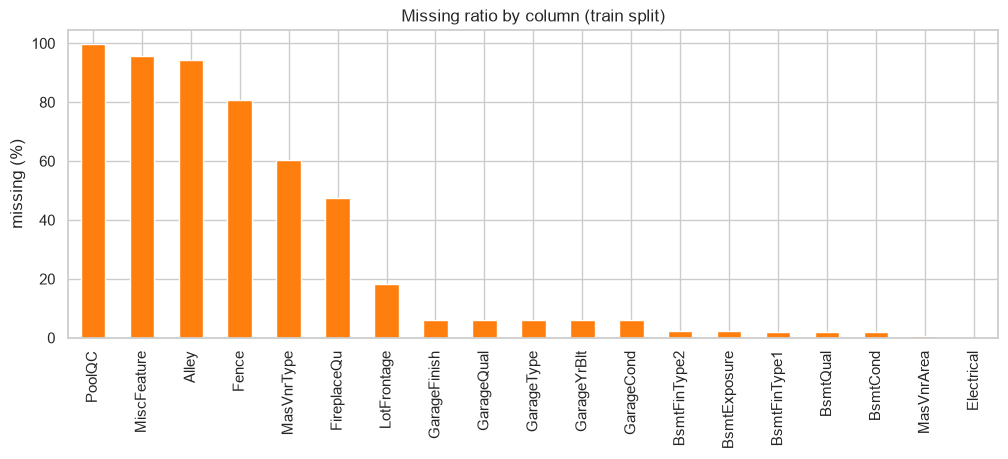

PoolQC 결측    False  True 
PoolArea==0              
False            4      0
True             0    930
GarageType 결측  False  True 
GarageArea==0              
False            876      0
True               0     58


In [5]:
# ===== 1-4. 결측치 현황 =====
missing = pd.DataFrame({
    '학습_%': eda_df.isnull().mean() * 100,
    'test_%':  test_df.isnull().mean() * 100,
}).round(1)
missing = missing[(missing['학습_%'] > 0) | (missing['test_%'] > 0)].sort_values('학습_%', ascending=False)
print(missing)

missing['학습_%'].plot.bar(figsize=(12, 4), color='tab:orange')
plt.ylabel('missing (%)'); plt.title('Missing ratio by column (train split)'); plt.show()

# "없음"을 뜻하는 결측인지 확인: 시설 면적이 0인 집 = 품질 칸이 빈 집?
print(pd.crosstab(eda_df['PoolArea'] == 0, eda_df['PoolQC'].isnull(),
                  rownames=['PoolArea==0'], colnames=['PoolQC 결측']))
print(pd.crosstab(eda_df['GarageArea'] == 0, eda_df['GarageType'].isnull(),
                  rownames=['GarageArea==0'], colnames=['GarageType 결측']))

**결측치 해석**

- PoolQC 99.6%, MiscFeature 95.6%, Alley 94.2% 등은 결측이 대부분이다
- 교차표: **PoolArea가 0인 집 = PoolQC가 빈 집**(930채 완전 일치), GarageArea가 0인 집 = GarageType이 빈 집(58채 일치)
- → 이 빈칸은 '모름'이 아니라 '시설 없음'이다. 최빈값으로 채우면 없는 수영장이 생기므로, 범주형은 `'None'`, 수치형은 `0`으로 채운다 (2-1)

---
## 2. 데이터 가공

**전처리 원칙:** 모든 기준값(중앙값, 최빈값, 왜도 컬럼, 원핫 컬럼, 지울 열)은 **학습 데이터로만 계산**(`fit_` 함수)하고, 검증·test에는 계산된 값을 **적용만** 한다(`apply_`/`fill_` 함수). 검증·test 정보가 학습에 새는 것(데이터 누수)을 막기 위해서다.

| 단계 | 방법 | 이유 |
|---|---|---|
| 2-1 결측치 | 시설 없음 → `'None'`/`0`, LotFrontage → 동네별 중앙값, GarageYrBlt → 집 건축연도, 진짜 누락(Electrical 등) → 최빈값 | 결측의 의미에 맞게 채움 |
| 2-2 순서형 인코딩 | 품질 등급 10개: None 0 < Po 1 < Fa 2 < TA 3 < Gd 4 < Ex 5 | 등급에는 순서가 있으므로 숫자로 |
| 2-3 파생 변수 | TotalSF, TotalBath, HouseAge, RemodAge, TotalPorchSF, QualSF | 흩어진 면적·욕실 정보를 합쳐 모델이 쓰기 쉽게 |
| 2-4 log1p | 왜도 > 0.75이면서 변환 후 실제로 대칭에 가까워지는 20개 컬럼 | 한쪽으로 쏠린 분포 완화 |
| 2-5 원핫 인코딩 | 나머지 범주형 → 0/1 열, test는 학습 컬럼에 맞춤 | 순서 없는 범주 |
| 2-6 중복 열 제거 | 값이 완전히 같은 열 삭제 | 같은 정보 중복 |
| 2-8 이상치 제거 | 면적 4,000sqft 초과 & 가격 30만 달러 미만 2채를 학습 데이터에서 제거 | 일반적이지 않은 거래(Partial)이며 test에는 이런 집이 없음 |

In [6]:
# ===== 2-1. 결측치 처리 =====
NONE_COLS = ['Alley', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
             'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
             'PoolQC', 'Fence', 'MiscFeature', 'MasVnrType']                 # 빈칸 = 시설 없음 → 'None'
ZERO_COLS = ['MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF',
             'BsmtFullBath', 'BsmtHalfBath', 'GarageCars', 'GarageArea']     # 시설 없음 → 0
MODE_COLS = ['MasVnrType', 'BsmtExposure', 'BsmtFinType2', 'Electrical']     # 진짜 누락 → 최빈값

def fit_missing(df):                                   # 학습 데이터로만 기준값 계산
    return {
        'lot_by_nbhd': df.groupby('Neighborhood')['LotFrontage'].median(),
        'lot_overall': df['LotFrontage'].median(),
        'mode': {col: df[col].mode()[0] for col in MODE_COLS},
    }

def fill_missing(df, stats):                           # 계산된 기준값만 적용
    df = df.copy()
    # 예외 먼저: 장식재 면적은 있는데 종류만 빈 집 / 지하실은 있는데 노출도·마감2만 빈 집
    m = df['MasVnrType'].isnull() & (df['MasVnrArea'] > 0)
    df.loc[m, 'MasVnrType'] = stats['mode']['MasVnrType']
    has_bsmt = df['BsmtQual'].notnull()
    for col in ['BsmtExposure', 'BsmtFinType2']:
        df.loc[df[col].isnull() & has_bsmt, col] = stats['mode'][col]
    # 없음 채우기
    df[NONE_COLS] = df[NONE_COLS].fillna('None')
    df[ZERO_COLS] = df[ZERO_COLS].fillna(0)
    # LotFrontage: 동네별 중앙값 → (처음 보는 동네는) 전체 중앙값
    df['LotFrontage'] = (df['LotFrontage'].fillna(df['Neighborhood'].map(stats['lot_by_nbhd']))
                                          .fillna(stats['lot_overall']))
    # GarageYrBlt: 차고 없는 집은 집 건축연도로
    df['GarageYrBlt'] = df['GarageYrBlt'].fillna(df['YearBuilt'])
    df['Electrical'] = df['Electrical'].fillna(stats['mode']['Electrical'])
    return df


In [7]:
# ===== 2-2. 품질 등급 숫자 매핑 =====
QUAL_COLS = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC',
             'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC']
QUAL_MAP = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}

def encode_ordinal(df):                                # 정해진 대응표라 fit 불필요
    df = df.copy()
    for col in QUAL_COLS:
        df[col] = df[col].map(QUAL_MAP)
    return df


In [8]:
# ===== 2-3. 파생 변수 추가 =====
PORCH_COLS = ['OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'WoodDeckSF']

def add_features(df):                                  # 기존 컬럼끼리 계산만 하므로 fit 불필요
    df = df.copy()
    df['TotalSF'] = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']                  # 지하 + 1층 + 2층 총면적
    df['TotalBath'] = (df['FullBath'] + 0.5 * df['HalfBath']
                       + df['BsmtFullBath'] + 0.5 * df['BsmtHalfBath'])                  # 총 욕실 수 (반욕실은 0.5개)
    df['HouseAge'] = (df['YrSold'] - df['YearBuilt']).clip(lower=0)                     # 팔릴 때 집 나이
    df['RemodAge'] = (df['YrSold'] - df['YearRemodAdd']).clip(lower=0)                  # 리모델링 후 경과 연수
    df['TotalPorchSF'] = df[PORCH_COLS].sum(axis=1)                                      # 현관·데크 총면적
    df['QualSF'] = df['OverallQual'] * df['GrLivArea']                                   # 품질 × 면적 (좋은 집이 넓으면 더 비쌈)
    return df

NEW_FEATURES = ['TotalSF', 'TotalBath', 'HouseAge', 'RemodAge', 'TotalPorchSF', 'QualSF']


In [9]:
# ===== 2-4. 왜도가 큰 변수 log1p =====
SKEW_THRESHOLD = 0.75

def fit_skew(df):                                      # 왜도 > 0.75 이면서 log1p 후 실제로 개선되는 컬럼만
    num = df.select_dtypes(include='number').columns.drop(QUAL_COLS)
    before = df[num].skew()
    cand = before[before > SKEW_THRESHOLD].index
    after = np.log1p(df[cand]).skew()
    return cand[after.abs() < before[cand].abs()].tolist()

def apply_log(df, skew_cols):
    df = df.copy()
    df[skew_cols] = np.log1p(df[skew_cols])
    return df


In [10]:
# ===== 2-5. 원핫 인코딩 =====
def fit_onehot(df):                                    # 학습 데이터의 원핫 컬럼 목록 기억
    return pd.get_dummies(df, dtype=int).columns

def apply_onehot(df, onehot_cols):                     # 같은 컬럼으로 맞춤 (없는 컬럼은 0, 처음 보는 범주는 버림)
    return pd.get_dummies(df, dtype=int).reindex(columns=onehot_cols, fill_value=0)


In [11]:
# ===== 2-6. 값이 완전히 같은 열 제거 =====
def fit_dup_cols(df):                                  # 학습 데이터에서 앞의 열과 값이 완전히 같은 열 목록
    return df.columns[df.T.duplicated()].tolist()      # 전치(.T) → 열이 행이 됨 → 중복 행 찾기

def drop_dup_cols(df, dup_cols):
    return df.drop(columns=dup_cols)


In [12]:
# ===== 2-7. 확인: 학습 데이터로 기준 계산 → 세 데이터에 적용 =====
miss_stats = fit_missing(X_tr)
X_tr_o, X_val_o, X_test_o = [add_features(encode_ordinal(fill_missing(d, miss_stats))) for d in (X_tr, X_val, X_test)]
skew_cols = fit_skew(X_tr_o)
X_tr_s, X_val_s, X_test_s = [apply_log(d, skew_cols) for d in (X_tr_o, X_val_o, X_test_o)]
onehot_cols = fit_onehot(X_tr_s)
X_tr_p, X_val_p, X_test_p = [apply_onehot(d, onehot_cols) for d in (X_tr_s, X_val_s, X_test_s)]
dup_cols = fit_dup_cols(X_tr_p)
print('값이 같아서 지울 열:', dup_cols)
X_tr_p, X_val_p, X_test_p = [drop_dup_cols(d, dup_cols) for d in (X_tr_p, X_val_p, X_test_p)]

print('log1p 변환 컬럼:', len(skew_cols), '개')
print('shape → 학습:', X_tr_p.shape, '/ 검증:', X_val_p.shape, '/ test:', X_test_p.shape)
print('결측치:', X_tr_p.isnull().sum().sum(), X_val_p.isnull().sum().sum(), X_test_p.isnull().sum().sum())
print('숫자가 아닌 컬럼:', X_tr_p.select_dtypes(exclude='number').shape[1])
print('PoolQC 분포(학습):', X_tr_o['PoolQC'].value_counts().to_dict())

# 새 변수와 SalePrice의 상관계수 (학습 데이터)
print(X_tr_o[NEW_FEATURES + ['GrLivArea', 'OverallQual']].corrwith(np.log1p(y_tr)).sort_values(ascending=False).round(3))

값이 같아서 지울 열: ['BldgType_2fmCon', 'BldgType_Duplex', 'Exterior2nd_CBlock', 'BsmtFinType1_None', 'BsmtFinType2_None', 'GarageFinish_None']
log1p 변환 컬럼: 20 개
shape → 학습: (934, 269) / 검증: (234, 269) / test: (292, 269)
결측치: 0 0 0
숫자가 아닌 컬럼: 0
PoolQC 분포(학습): {0: 930, 2: 2, 5: 1, 4: 1}
OverallQual     0.813
QualSF          0.781
TotalSF         0.754
GrLivArea       0.699
TotalBath       0.665
TotalPorchSF    0.378
HouseAge       -0.552
RemodAge       -0.563
dtype: float64


**전처리 결과 확인**

- 세 데이터 모두 **269개 열**, 결측치 0, 숫자가 아닌 열 0 → 모델에 바로 넣을 수 있다
- 값이 완전히 같아서 지운 열 6개: 예) `MSSubClass_190`(2가구 주택 번호) = `BldgType_2fmCon`(2가구 주택), 지하실이 없으면 `BsmtFinType1_None` = `BsmtFinType2_None`
- **파생 변수 효과:** `QualSF`(품질×면적) 0.781, `TotalSF`(총면적) 0.754로 원래 변수 GrLivArea(0.699)보다 log 가격과 상관이 높다

In [13]:
# ===== 2-8. 이상치 2채 제거 (면적 4000 초과 & 가격 30만 미만) =====
def outlier_mask(X, y):
    return (X['GrLivArea'] > 4000) & (y < 300000)

is_out = outlier_mask(X_tr, y_tr).values               # 학습 데이터 이상치 위치 (True/False 배열)
print('학습 데이터 이상치:', is_out.sum(), '/ 검증 데이터 이상치:', outlier_mask(X_val, y_val).sum())
X_tr_clean, y_tr_clean = X_tr[~is_out], y_tr[~is_out]  # 이상치 2채 제거 (932채)
print('이상치 제거 후 학습 데이터:', X_tr_clean.shape)

학습 데이터 이상치: 2 / 검증 데이터 이상치: 0
이상치 제거 후 학습 데이터: (932, 79)


---
## 3. 모델 설정

| 구성 요소 | 설정 | 이유 |
|---|---|---|
| 전처리 | `HousePreprocessor` (2단계 함수들을 하나로 묶음) | Pipeline 안에서 학습 데이터로만 기준값을 계산 → 데이터 누수 방지 |
| 타겟 | `log1p(SalePrice)`로 학습, 예측 후 `expm1`로 되돌림 (`TransformedTargetRegressor`) | 오른쪽 꼬리가 긴 가격 분포를 대칭에 가깝게 |
| 스케일링 | SVR 앞에만 `RobustScaler` | SVR은 거리 기반이라 변수 크기를 맞춰야 함. 트리 모델은 영향 없음 |
| 모델 1 | **SVR** (RBF 커널) C=50, epsilon=0.005, gamma=0.0005 | 면적·품질과 가격의 휘어진 관계를 학습 |
| 모델 2 | **GradientBoosting** learning_rate=0.03, 트리 1,000개, 깊이 4, subsample=0.8 | 트리 기반이라 SVR과 다른 방식으로 틀림 → 섞으면 서로 보완 |
| 결합 | SVR 0.7 + GradientBoosting 0.3 가중 평균 × 보정 계수 1.01 | log 타겟 모델은 달러 기준으로 약간 낮게 예측하므로 보정 |

하이퍼파라미터, 가중치, 보정 계수는 학습 데이터 5-fold 교차검증으로 미리 정한 값이다.

In [14]:
# ===== 3-1. 전처리를 sklearn 부품(클래스)으로 포장 =====
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor

class HousePreprocessor(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):                          # 학습 데이터로만 기준값 계산
        self.miss_stats_ = fit_missing(X)
        X1 = add_features(encode_ordinal(fill_missing(X, self.miss_stats_)))
        self.skew_cols_ = fit_skew(X1)
        X1 = apply_log(X1, self.skew_cols_)
        self.onehot_cols_ = fit_onehot(X1)
        self.dup_cols_ = fit_dup_cols(apply_onehot(X1, self.onehot_cols_))   # 값이 같은 열 목록도 학습 데이터로만
        return self

    def transform(self, X):                            # 저장된 기준값만 적용
        X1 = add_features(encode_ordinal(fill_missing(X, self.miss_stats_)))
        X1 = apply_log(X1, self.skew_cols_)
        return drop_dup_cols(apply_onehot(X1, self.onehot_cols_), self.dup_cols_)


# [전처리] → [스케일러(SVR만)] → [모델(학습 때 가격을 log1p, 예측 때 expm1로 되돌림)]
def make_pipe(model, scale=True):
    model = TransformedTargetRegressor(regressor=model, func=np.log1p, inverse_func=np.expm1)
    steps = [('prep', HousePreprocessor())]
    if scale:
        steps.append(('scaler', RobustScaler()))       # 중앙값·사분위 범위 사용 → 극단값 영향이 적음
    steps.append(('model', model))
    return Pipeline(steps)



In [15]:
# ===== 3-2. 최종 모델 설정 =====
# SVR: C=오차 벌점, epsilon=무시할 오차 폭, gamma=커널 범위 (RBF 커널)
svr_pipe = make_pipe(SVR(C=50, epsilon=0.005, gamma=0.0005), scale=True)

# GradientBoosting: 트리를 순서대로 쌓아 앞 트리의 오차를 줄임 (트리 모델이라 스케일링 없음)
gbr_pipe = make_pipe(GradientBoostingRegressor(learning_rate=0.03, n_estimators=1000, max_depth=4,
                                               subsample=0.8, random_state=42), scale=False)

MODELS = {'SVR': svr_pipe, 'GradientBoosting': gbr_pipe}

WEIGHTS = {'SVR': 0.7, 'GradientBoosting': 0.3}        # 최종 가중 평균 비율
SCALE_K = 1.01                                         # 보정 계수: log 타겟 모델이 낮게 예측하는 만큼 보정

# 잔차 이상치를 찾을 때 쓰는 비율과 5-fold
RESID_WEIGHTS = {'SVR': 0.8, 'GradientBoosting': 0.2}
kf = KFold(n_splits=5, shuffle=True, random_state=42)

for name, pipe in MODELS.items():
    print(name, '→', pipe.named_steps['model'].regressor)

SVR → SVR(C=50, epsilon=0.005, gamma=0.0005)
GradientBoosting → GradientBoostingRegressor(learning_rate=0.03, max_depth=4, n_estimators=1000,
                          random_state=42, subsample=0.8)


---
## 4. 모델 학습

1. **잔차 이상치 찾기:** 학습 데이터 932채를 5-fold로 나눠, 각 집을 그 집을 학습에 쓰지 않은 모델로 예측한다(OOF 예측). log 오차가 표준편차의 3배를 넘는 집은 다른 집들과 가격 규칙이 다른 집으로 보고 학습에서 뺀다.
2. **최종 학습:** 학습 데이터(이상치 2채 + 잔차 이상치 제외) + 검증 데이터로 두 모델을 학습한다.

In [16]:
# ===== 4-1. 잔차 이상치 찾기 =====
# 학습 데이터 932채를 5-fold로 나눠, 각 집을 '그 집을 학습에 쓰지 않은 모델'로 예측 (OOF 예측)
# 예측이 크게 틀린 집 = 다른 집들과 가격 규칙이 다른 집 → 최종 학습에서 뺀다
FOLDS = []
for tr_idx, va_idx in kf.split(X_tr):
    FOLDS.append((tr_idx[~is_out[tr_idx]], va_idx[~is_out[va_idx]]))   # 이상치 2채는 학습·예측 모두 제외

oof = pd.DataFrame(index=X_tr.index, columns=list(MODELS), dtype=float)
for tr_idx, va_idx in FOLDS:
    for name, pipe in MODELS.items():
        model = clone(pipe).fit(X_tr.iloc[tr_idx], y_tr.iloc[tr_idx])
        oof.iloc[va_idx, oof.columns.get_loc(name)] = model.predict(X_tr.iloc[va_idx])
oof = oof.dropna()                                     # 이상치 2채 행 제거 → 932채

oof_blend = sum(oof[name] * w for name, w in RESID_WEIGHTS.items())
log_resid = np.log1p(y_tr[oof.index]) - np.log1p(oof_blend)               # log 단위 오차
resid_out = log_resid.index[log_resid.abs() > 3 * log_resid.std()]       # 표준편차 3배 초과

print('잔차 이상치:', len(resid_out), '채')
print(pd.DataFrame({'실제가': y_tr[resid_out], 'OOF예측': oof_blend[resid_out].round(),
                    'SaleCondition': X_tr.loc[resid_out, 'SaleCondition'],
                    'Neighborhood': X_tr.loc[resid_out, 'Neighborhood']}).sort_values('실제가'))



잔차 이상치: 14 채
         실제가     OOF예측 SaleCondition Neighborhood
1069   34900   62132.0       Abnorml       IDOTRR
379    35311   50108.0       Abnorml       IDOTRR
727    40000   87184.0        Normal       IDOTRR
520    55993   92737.0        Alloca       IDOTRR
805    60000  104008.0       Abnorml      Edwards
279    62383  119156.0        Normal       Sawyer
22     66500   96303.0       Abnorml      OldTown
124    82500  159489.0        Family       NWAmes
552    84500  131760.0       Abnorml      Mitchel
763    89471  126512.0        Alloca      OldTown
386   121500  178578.0        Normal       Sawyer
1124  135000   85920.0       Abnorml        NAmes
164   143000  238519.0       Partial      ClearCr
815   147000  282284.0       Partial      Somerst


**잔차 이상치 14채:** 14채 중 9채가 Abnorml(비정상 거래)·Alloca(인접 부지 매입)·Family(가족 간 거래)이고, 대부분 IDOTRR·OldTown 등 저가 동네의 싼 집이다. 시장 가격과 다른 이유로 거래된 집이 많아 일반적인 가격 규칙을 배우는 데 방해가 된다고 보고 제외했다. 학습에서만 빼고, test 예측 대상은 그대로다.

In [17]:
# ===== 4-2. 최종 학습 (학습 + 검증 데이터) =====
X_tr_r, y_tr_r = X_tr_clean.drop(resid_out), y_tr_clean.drop(resid_out)   # 이상치 2채 + 잔차 이상치 제거
X_full = pd.concat([X_tr_r, X_val])                    # 검증 세트는 이상치 0채라 그대로 붙임
y_full = pd.concat([y_tr_r, y_val])
print('최종 학습 데이터:', X_full.shape)

final_models = {name: clone(pipe).fit(X_full, y_full) for name, pipe in MODELS.items()}
print('학습 완료:', list(final_models))

최종 학습 데이터: (1152, 79)


학습 완료: ['SVR', 'GradientBoosting']


**최종 학습 데이터 1,152채** = 학습 934채 − 이상치 2채 − 잔차 이상치 14채 + 검증 234채. 정답이 있는 데이터를 최대한 활용하기 위해 검증 데이터도 함께 학습했다. 전처리 기준값(중앙값, 원핫 컬럼 등)과 스케일러도 Pipeline 안에서 이 1,152채로 다시 계산된다.

---
## 5. 데이터 예측, 제출

In [18]:
# ===== 5-1. test 예측 =====
test_pred_each = pd.DataFrame({name: m.predict(X_test) for name, m in final_models.items()})
test_pred = sum(test_pred_each[name] * w for name, w in WEIGHTS.items()) * SCALE_K   # 가중 평균 → 보정 계수
print(test_pred.describe().round(0))



count       292.0
mean     183536.0
std       77721.0
min       62005.0
25%      133049.0
50%      163265.0
75%      216215.0
max      596135.0
dtype: float64


In [19]:
# ===== 5-2. 제출 파일 생성 =====
submission = pd.DataFrame({'Id': test_id, 'SalePrice': test_pred.values})
submission.to_csv('submission.csv', index=False)

# --- 제출 전 점검 ---
print('shape:', submission.shape)
print('결측:', submission['SalePrice'].isnull().sum(), '/ 0 이하 가격:', (submission['SalePrice'] <= 0).sum())
print(submission.head(3))

shape: (292, 2)
결측: 0 / 0 이하 가격: 0
    Id      SalePrice
0   86  268564.648935
1  227  273043.509341
2  492  140596.962458
